# Assignment - Analyzing the IMDB Top 1000 Movies

In this assignment, you will be working with this dataset of IMDB top 1000 movies.

Source: https://www.kaggle.com/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows

In [1]:
import pandas as pd
import numpy as np

In [2]:
# Read the data file "imdb_top_1000.csv" to a dataframe named "imdb"
imdb = pd.read_csv('https://raw.githubusercontent.com/jiexunli-wwu/mis433/refs/heads/main/data/imdb_top_1000.csv', header=0)
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [3]:
# Describe the dataframe using the info() method.
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [4]:
# List all the column names:
imdb.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='object')

## Part 1: Data Manipulation

Redo the following to clean the data.

In [5]:
# Count the number of movies in each "Released_Year".
# Hint: value_counts()
imdb.value_counts("Released_Year")


,count
Released_Year,
2014,32
2004,31
2009,29
2016,28
2013,28
...,...
1936,1
1930,1
1921,1


In [6]:
# In this dataset, there is a movie with an error in "Released_Year".
# Hint: Released_Year should be a 4-digit integer but this movie's year is not.
# Find this movie.
# Find rows where Released_Year is not a 4-digit year
imdb[imdb['Released_Year'] == 'PG']

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
966,https://m.media-amazon.com/images/M/MV5BNjEzYj...,Apollo 13,PG,U,140 min,"Adventure, Drama, History",7.6,NASA must devise a strategy to return Apollo 1...,77.0,Ron Howard,Tom Hanks,Bill Paxton,Kevin Bacon,Gary Sinise,269197,"173,837,933"


In [7]:
# Correct the values for the corresponding columns ("Released_Year" and "Certificate").
# You may want to look up this movie on www.imdb.com.
# Hint: You can set value for a particular row by: df.loc[row_index, column_name] = new_value
imdb.loc[966,'Released_Year']=1995
imdb.loc[966,'Certificate']='PG'
imdb.loc[966]

,966
Poster_Link,https://m.media-amazon.com/images/M/MV5BNjEzYj...
Series_Title,Apollo 13
Released_Year,1995
Certificate,PG
Runtime,140 min
Genre,"Adventure, Drama, History"
IMDB_Rating,7.6
Overview,NASA must devise a strategy to return Apollo 1...
Meta_score,77.0
Director,Ron Howard


In [8]:
# Change the data type of "Released_Year" to int
imdb['Released_Year']=imdb['Released_Year'].astype(int)

In [9]:
imdb.dtypes

,0
Poster_Link,object
Series_Title,object
Released_Year,int64
Certificate,object
Runtime,object
Genre,object
IMDB_Rating,float64
Overview,object
Meta_score,float64
Director,object


In [10]:
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb.loc[
    (imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >= 8.5),
    ['Series_Title', 'Released_Year', 'Certificate', 'Gross']
].sort_values(by='Gross', ascending=False)

,Series_Title,Released_Year,Certificate,Gross
19,Gisaengchung,2019,A,"53,367,844"
33,Joker,2019,A,"335,451,311"
8,Inception,2010,UA,"292,576,195"
21,Interstellar,2014,UA,"188,020,017"
35,The Intouchables,2011,UA,"13,182,281"
34,Whiplash,2014,A,"13,092,000"
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [11]:
# Does the sorting result look right to you? What's the problem?
#Gross is a string

In [12]:
# Resolve this problem of "Gross" and convert its data type to float
# Hint: You may find this webpage useful:
# https://stackoverflow.com/questions/28986489/how-to-replace-text-in-a-column-of-a-pandas-dataframe

imdb['Gross'] = imdb['Gross'].replace(',', '', regex=True).astype(float)

In [13]:
# Next, redo the sorting on Gross

# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb.loc[
    (imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >= 8.5),
    ['Series_Title', 'Released_Year', 'Certificate', 'Gross']
].sort_values(by='Gross', ascending=False)

,Series_Title,Released_Year,Certificate,Gross
33,Joker,2019,A,335451311.0
8,Inception,2010,UA,292576195.0
21,Interstellar,2014,UA,188020017.0
19,Gisaengchung,2019,A,53367844.0
35,The Intouchables,2011,UA,13182281.0
34,Whiplash,2014,A,13092000.0
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [14]:
# Add a new column "Runtime_min" by removing the substring " min" in "Runtime"
# Set its data type as int
# Hint: https://stackoverflow.com/questions/36505847/substring-of-an-entire-column-in-pandas-dataframe
imdb['Runtime_min'] = imdb['Runtime'].str.replace(' min', '', regex=False).astype(int)

In [15]:
# Add a new column "Age_Years" by the expression: Current year - Released_Year
imdb['Age_Years'] = 2026 - imdb['Released_Year']

In [16]:
# Add a new column "Decade" with values as 1980, 1990, 2000, 2010, 2020, etc.
imdb['Decade'] = (imdb['Released_Year'] // 10) * 10
imdb

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_min,Age_Years,Decade
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142,32,1990
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0,175,54,1970
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0,152,18,2000
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0,202,52,1970
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0,96,69,1950
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,https://m.media-amazon.com/images/M/MV5BNGEwMT...,Breakfast at Tiffany's,1961,A,115 min,"Comedy, Drama, Romance",7.6,A young New York socialite becomes interested ...,76.0,Blake Edwards,Audrey Hepburn,George Peppard,Patricia Neal,Buddy Ebsen,166544,NaN,115,65,1960
996,https://m.media-amazon.com/images/M/MV5BODk3Yj...,Giant,1956,G,201 min,"Drama, Western",7.6,Sprawling epic covering the life of a Texas ca...,84.0,George Stevens,Elizabeth Taylor,Rock Hudson,James Dean,Carroll Baker,34075,NaN,201,70,1950
997,https://m.media-amazon.com/images/M/MV5BM2U3Yz...,From Here to Eternity,1953,Passed,118 min,"Drama, Romance, War",7.6,"In Hawaii in 1941, a private is cruelly punish...",85.0,Fred Zinnemann,Burt Lancaster,Montgomery Clift,Deborah Kerr,Donna Reed,43374,30500000.0,118,73,1950
998,https://m.media-amazon.com/images/M/MV5BZTBmMj...,Lifeboat,1944,NaN,97 min,"Drama, War",7.6,Several survivors of a torpedoed merchant ship...,78.0,Alfred Hitchcock,Tallulah Bankhead,John Hodiak,Walter Slezak,William Bendix,26471,NaN,97,82,1940


## Part 2: Data Summarization

Done!

## Part 3: Data Visualization

Finish Part 1 (data manipulation) before you work through this section.

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

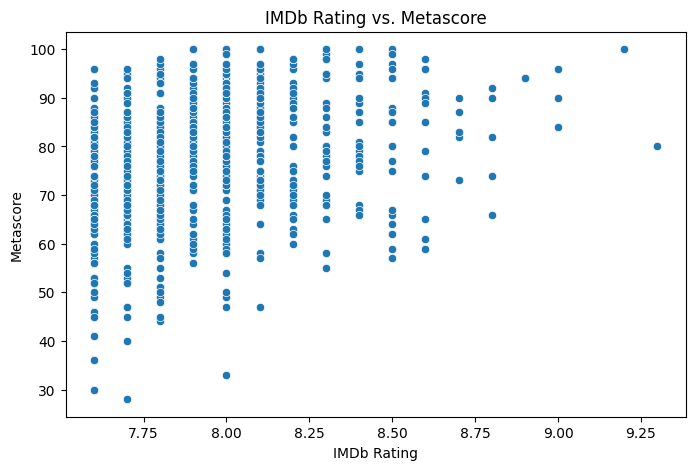

In [18]:
# Create a scatterplot of the two scores, "IMDB_Rating" and "Meta_score".
# In a sentence or two, describe what this pair of scores suggests about the movies.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score')

plt.title('IMDb Rating vs. Metascore')
plt.xlabel('IMDb Rating')
plt.ylabel('Metascore')
plt.show()

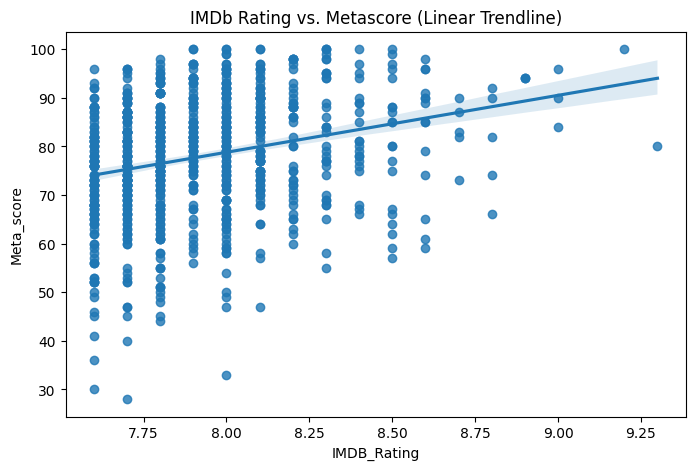

In [19]:
# Fit a trendline to show the relationship between the two scores.
# Hint: sns.regplot()
# Try a few values of the `order` argument (polynomial degree) for the trendline.
plt.figure(figsize=(8, 5))
sns.regplot(data=imdb, x='IMDB_Rating', y='Meta_score', order=1)
plt.title('IMDb Rating vs. Metascore (Linear Trendline)')
plt.show()


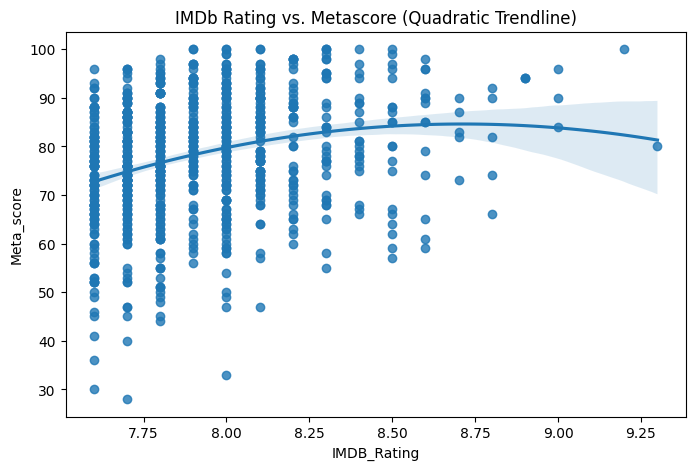

In [20]:
plt.figure(figsize=(8, 5))
sns.regplot(data=imdb, x='IMDB_Rating', y='Meta_score', order=2)
plt.title('IMDb Rating vs. Metascore (Quadratic Trendline)')
plt.show()

In [21]:
# Do any data points in the scatterplot surprise you?
# Try to identify a few such movies.
imdb.loc[
    imdb['Meta_score'].notna(),
    ['Series_Title', 'IMDB_Rating', 'Meta_score']
].assign(
    Rating_Diff=lambda x: (x['IMDB_Rating'] * 10 - x['Meta_score']).abs()
).sort_values(by='Rating_Diff', ascending=False).head(10)

,Series_Title,IMDB_Rating,Meta_score,Rating_Diff
788,I Am Sam,7.7,28.0,49.0
356,Tropa de Elite,8.0,33.0,47.0
942,The Butterfly Effect,7.6,30.0,46.0
917,Seven Pounds,7.6,36.0,40.0
735,Kai po che!,7.7,40.0,37.0
957,Fear and Loathing in Las Vegas,7.6,41.0,35.0
272,Pink Floyd: The Wall,8.1,47.0,34.0
648,The Boondock Saints,7.8,44.0,34.0
677,Predator,7.8,45.0,33.0
397,Bound by Honor,8.0,47.0,33.0


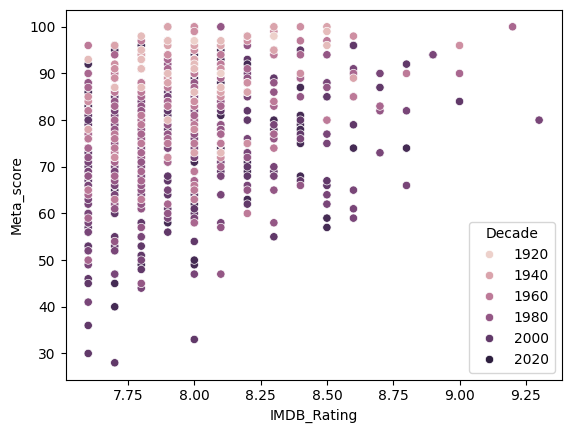

In [22]:
# In the scatterplot, use color to distinguish movies from different decades.
sns.scatterplot(data=imdb, x='IMDB_Rating', y='Meta_score', hue='Decade')
plt.show()

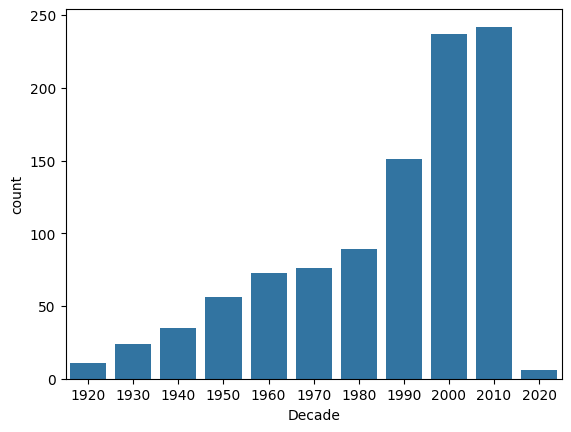

In [23]:
# Create a chart that shows how many movies fall into each decade.
sns.countplot(data=imdb, x='Decade')
plt.show()

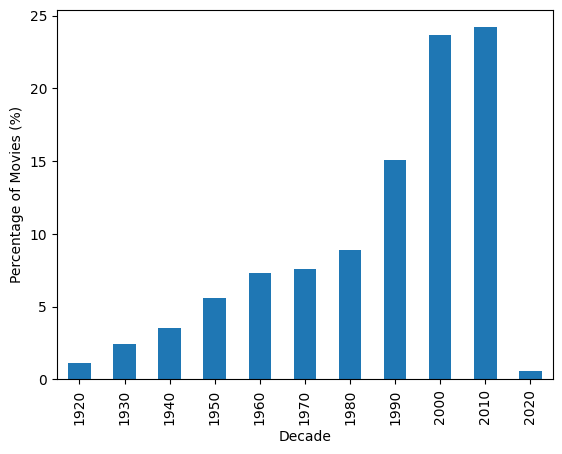

In [24]:
# Create a chart that shows the percentage of movies in each decade.
imdb['Decade'].value_counts(normalize=True).sort_index().mul(100).plot(kind='bar')
plt.ylabel('Percentage of Movies (%)')
plt.show()

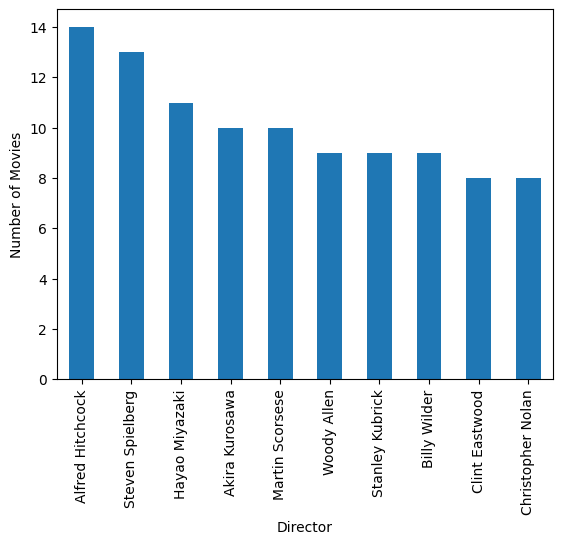

In [25]:
# Count movies by director.
# Show the top 10 directors by movie count in a bar chart.
imdb['Director'].value_counts().head(10).plot(kind='bar')
plt.xlabel('Director')
plt.ylabel('Number of Movies')
plt.show()

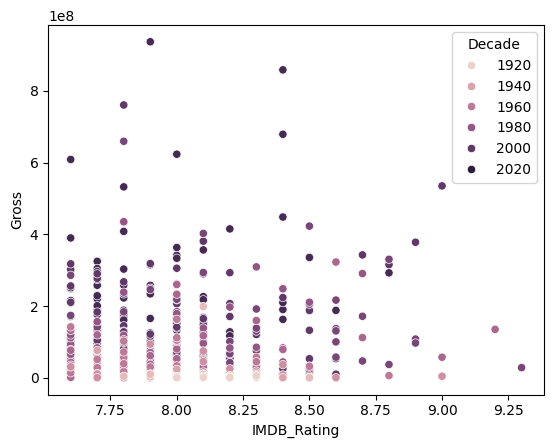

In [26]:
# Create a scatterplot of "IMDB_Rating" and "Gross".
# Use color to distinguish movies from different decades.
# Briefly interpret what the chart shows.
sns.scatterplot(data=imdb, x='IMDB_Rating', y='Gross', hue='Decade')
plt.show()

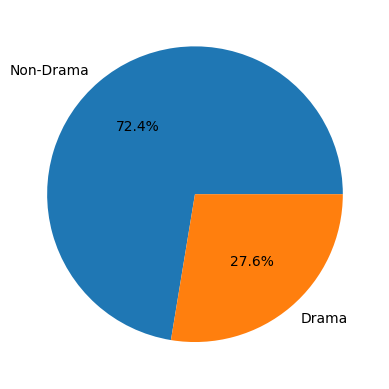

In [27]:
# Create a column named "Drama" that indicates whether a movie's Genre includes "Drama".
# Create a pie chart showing the share of drama vs. non-drama movies.
imdb['Drama'] = imdb['Genre'].str.contains('Drama', na=False)

imdb['Drama'].value_counts().plot(kind='pie', autopct='%1.1f%%', labels=['Non-Drama', 'Drama'])
plt.ylabel('')
plt.show()

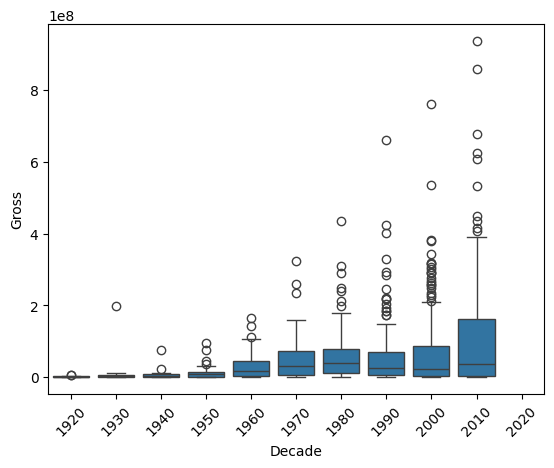

In [28]:
# Create a plot comparing Gross across decades.
sns.boxplot(data=imdb, x='Decade', y='Gross')
plt.xticks(rotation=45)
plt.show()

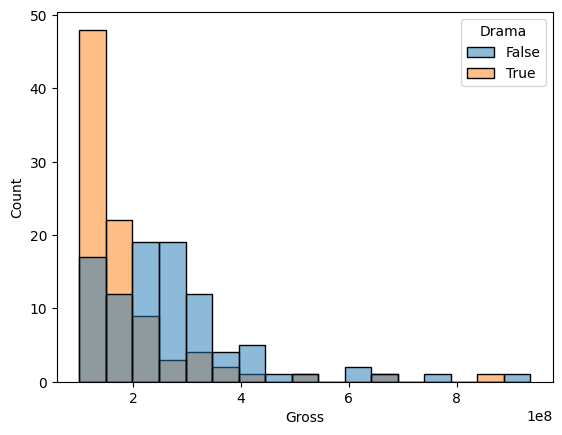

In [29]:
# For movies with Gross over $100 million:
# Create a histogram of Gross for drama vs. non-drama movies.
sns.histplot(
    data=imdb[imdb['Gross'] > 100_000_000],
    x='Gross',
    hue='Drama'
)
plt.show()

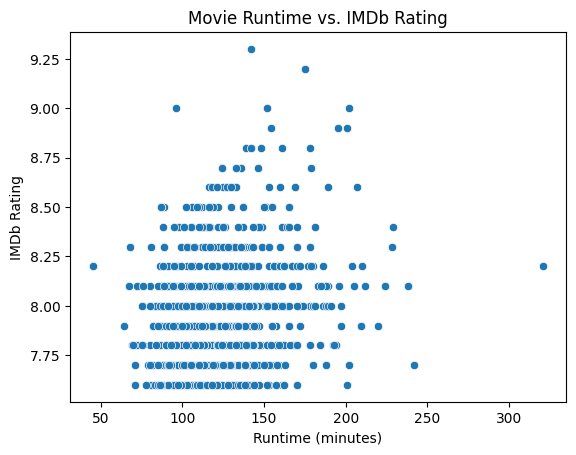

In [42]:
# Come up with two more questions about this dataset. Create one chart or figure for each.
# Question 1:Is there a relationship between movie runtime and IMDb rating, and how can it be shown using a scatter plot?
sns.scatterplot(data=imdb, x='Runtime_min', y='IMDB_Rating')
plt.xlabel('Runtime (minutes)')
plt.ylabel('IMDb Rating')
plt.title('Movie Runtime vs. IMDb Rating')
plt.show()

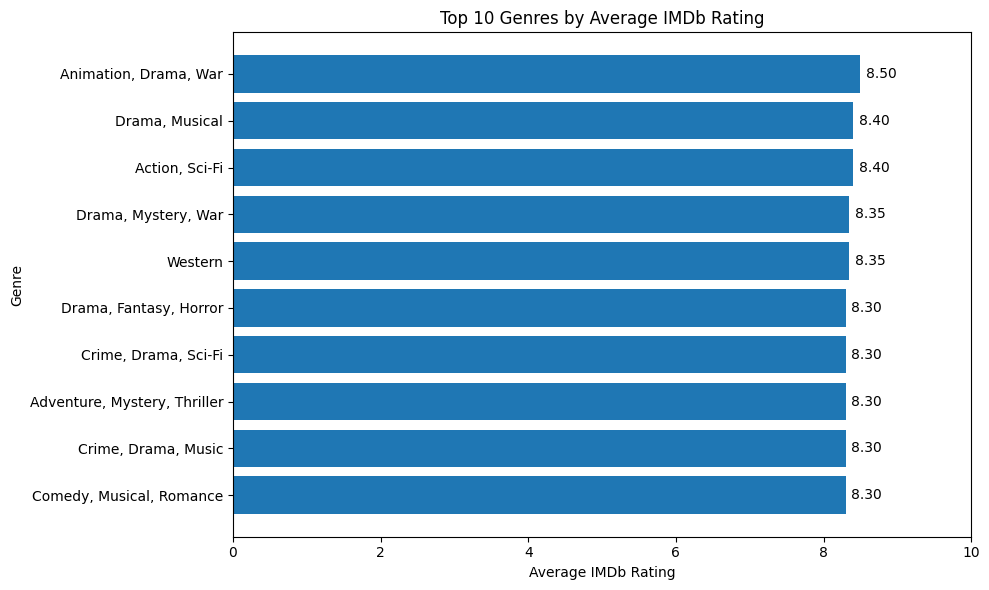

In [41]:
# Question 2:Which 10 genres have the highest average IMDb ratings, and how can their ratings be compared using a bar graph?
import matplotlib.pyplot as plt
genre_ratings = imdb.groupby('Genre')['IMDB_Rating'].mean()
top_10 = genre_ratings.nlargest(10).sort_values()
plt.figure(figsize=(10, 6))
bars = plt.barh(top_10.index, top_10.values)
plt.bar_label(bars, fmt='%.2f', padding=4)

plt.xlabel('Average IMDb Rating')
plt.ylabel('Genre')
plt.title('Top 10 Genres by Average IMDb Rating')
plt.xlim(0, 10)
plt.tight_layout()
plt.show()